<a href="https://colab.research.google.com/github/singhsapt9-glitch/Deep/blob/main/Weather.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

ਅਸਲੀ ਡੇਟਾ ਮਿਲਿਆ: 1826 ਦਿਨ

ਖ਼ਾਲੀ ਮੁੱਲ (missing values):
date        0
temp_max    0
temp_min    0
rain        0
wind        0
dtype: int64

ਡੇਟਾ ਦੇ ਪਹਿਲੇ 5 ਸਫ਼ੇ:
        date  temp_max  temp_min  rain  wind  year  month  dayofyear
0 2021-11-14      26.2      11.6   0.0  11.3  2021     11        318
1 2021-11-15      25.3      12.2   0.0  11.7  2021     11        319
2 2021-11-16      24.7      11.1   0.0  11.8  2021     11        320
3 2021-11-17      24.0       9.7   0.0  10.8  2021     11        321
4 2021-11-18      23.4      11.1   0.0  11.4  2021     11        322

ਅੰਕੜੇ:
       temp_max  temp_min     rain     wind
count   1826.00   1826.00  1826.00  1826.00
mean      29.59     18.12     1.97    12.80
std        7.35      7.50     6.18     4.39
min       12.10      1.70     0.00     3.40
25%       23.60     11.10     0.00     9.90
50%       31.35     19.40     0.00    11.80
75%       34.50     25.08     0.70    15.00
max       45.50     31.70    75.60    38.30

ਗ੍ਰਾਫ਼ ਸੇਵ ਹੋਇਆ: we

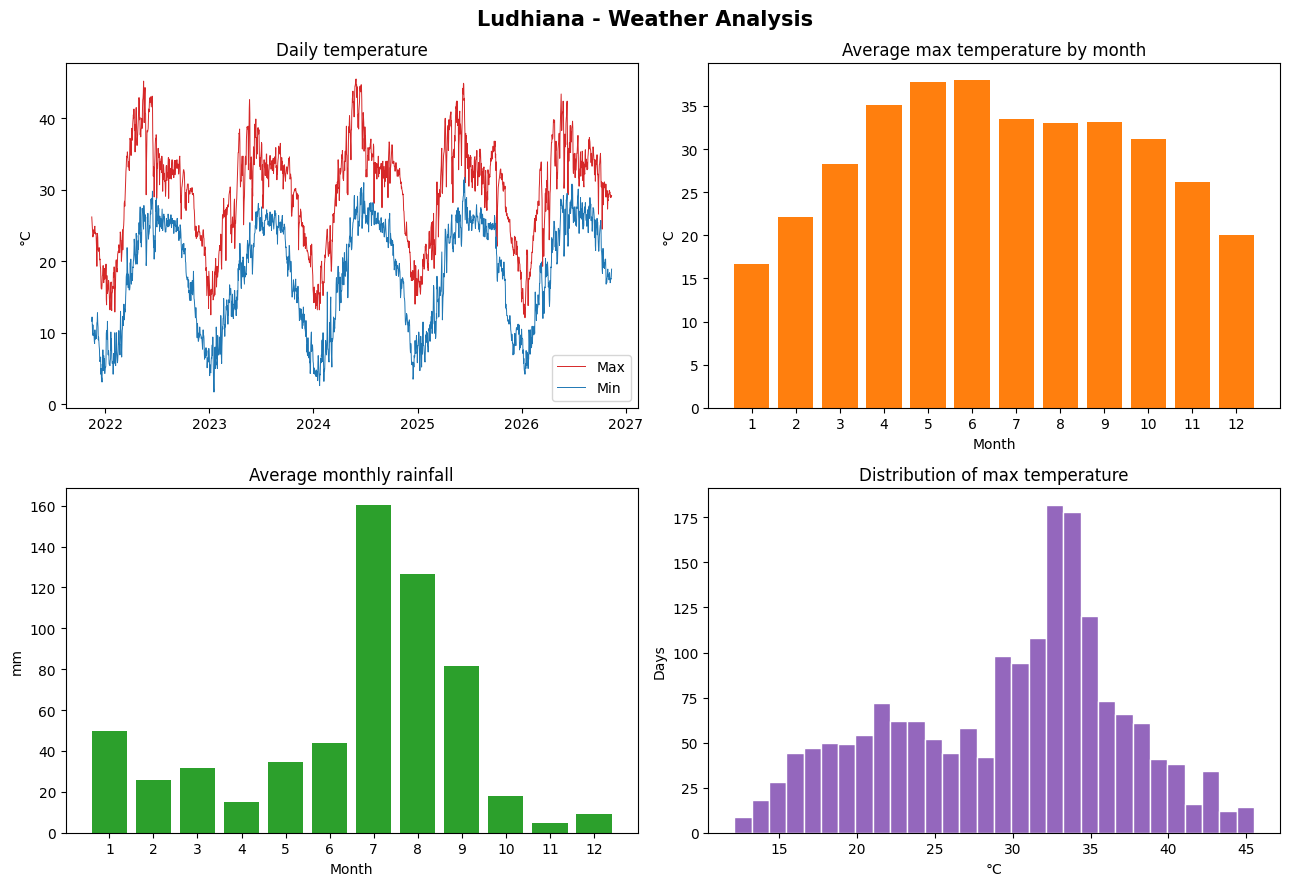

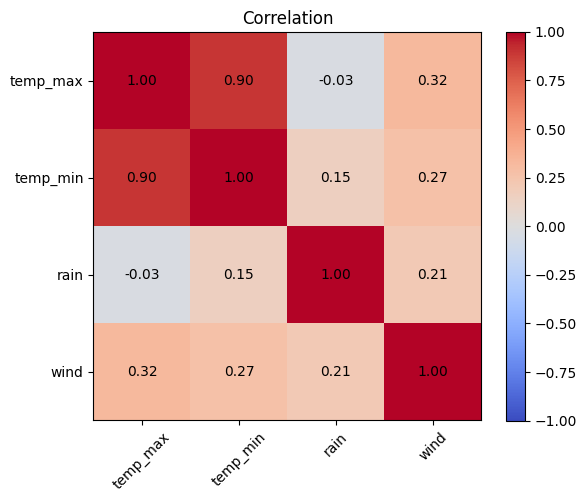

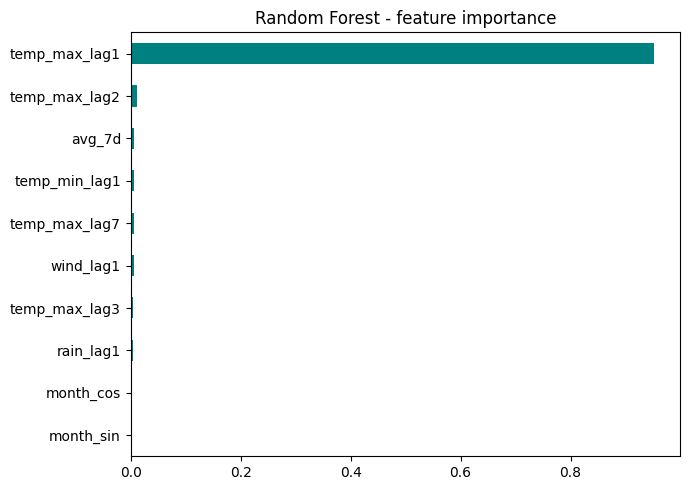

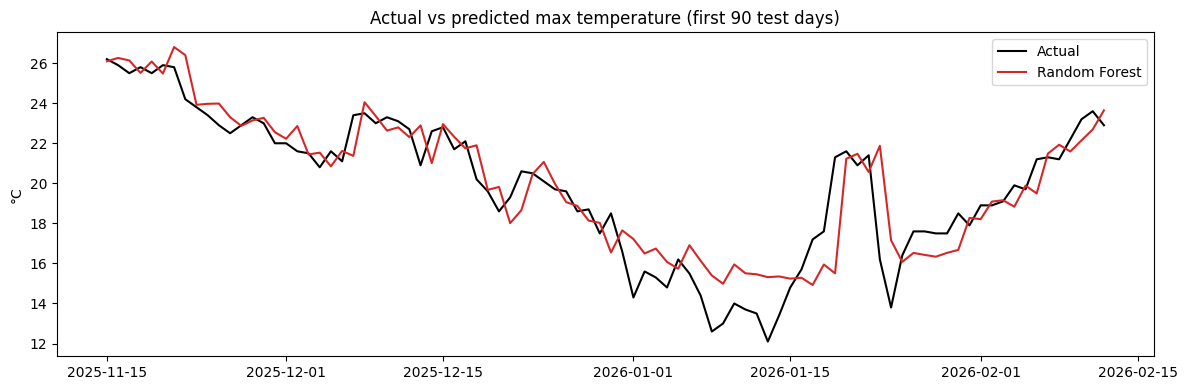

In [1]:
"""
Weather Analysis & Temperature Prediction - Ludhiana, Punjab
------------------------------------------------------------
1. ਪਿਛਲੇ 5 ਸਾਲ ਦਾ ਅਸਲੀ ਮੌਸਮ ਡੇਟਾ ਲੈਂਦਾ ਹੈ (Open-Meteo API, ਮੁਫ਼ਤ, ਕੋਈ key ਨਹੀਂ)
2. ਡੇਟਾ ਸਾਫ਼ ਕਰਦਾ ਹੈ ਅਤੇ EDA ਦੇ ਗ੍ਰਾਫ਼ ਬਣਾਉਂਦਾ ਹੈ
3. ਕੱਲ੍ਹ ਦਾ ਵੱਧ ਤੋਂ ਵੱਧ ਤਾਪਮਾਨ ਦੱਸਣ ਵਾਲੇ ਮਾਡਲ ਸਿਖਾਉਂਦਾ ਹੈ (Linear Regression, Random Forest)

ਚਲਾਉਣ ਤੋਂ ਪਹਿਲਾਂ:  pip install pandas numpy scikit-learn matplotlib requests
ਚਲਾਉਣ ਲਈ:        python weather_project.py
"""

from datetime import date, timedelta

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score

# ---------- ਸੈਟਿੰਗਾਂ ----------
CITY = "Ludhiana"
LAT, LON = 30.9010, 75.8573
YEARS = 5


# ---------- 1. ਡੇਟਾ ਲੈਣਾ ----------
def fetch_weather():
    """Open-Meteo ਤੋਂ ਰੋਜ਼ਾਨਾ ਮੌਸਮ ਡੇਟਾ ਲੈਂਦਾ ਹੈ। ਇੰਟਰਨੈੱਟ ਨਾ ਹੋਵੇ ਤਾਂ None ਮੋੜਦਾ ਹੈ।"""
    try:
        import requests

        end = date.today() - timedelta(days=7)          # ਤਾਜ਼ਾ ਦਿਨਾਂ ਦਾ ਡੇਟਾ ਥੋੜ੍ਹੀ ਦੇਰ ਬਾਅਦ ਆਉਂਦਾ ਹੈ
        start = end - timedelta(days=365 * YEARS)
        params = {
            "latitude": LAT,
            "longitude": LON,
            "start_date": start.isoformat(),
            "end_date": end.isoformat(),
            "daily": "temperature_2m_max,temperature_2m_min,precipitation_sum,wind_speed_10m_max",
            "timezone": "Asia/Kolkata",
        }
        r = requests.get("https://archive-api.open-meteo.com/v1/archive", params=params, timeout=30)
        r.raise_for_status()
        d = r.json()["daily"]
        df = pd.DataFrame(
            {
                "date": pd.to_datetime(d["time"]),
                "temp_max": d["temperature_2m_max"],
                "temp_min": d["temperature_2m_min"],
                "rain": d["precipitation_sum"],
                "wind": d["wind_speed_10m_max"],
            }
        )
        print(f"ਅਸਲੀ ਡੇਟਾ ਮਿਲਿਆ: {len(df)} ਦਿਨ")
        return df
    except Exception as e:
        print(f"API ਤੋਂ ਡੇਟਾ ਨਹੀਂ ਮਿਲਿਆ ({e})")
        return None


def make_fake_weather():
    """ਇੰਟਰਨੈੱਟ ਨਾ ਹੋਵੇ ਤਾਂ ਪ੍ਰੈਕਟਿਸ ਲਈ ਨਕਲੀ ਡੇਟਾ (ਸਿਰਫ਼ ਕੋਡ ਪਰਖਣ ਲਈ, ਅਸਲੀ ਨਹੀਂ)।"""
    rng = np.random.default_rng(42)
    dates = pd.date_range(end=date.today() - timedelta(days=7), periods=365 * YEARS)
    doy = dates.dayofyear.to_numpy()
    seasonal = 26 + 10 * np.sin((doy - 100) / 365 * 2 * np.pi)
    temp_max = seasonal + 6 + rng.normal(0, 2, len(dates))
    temp_min = seasonal - 6 + rng.normal(0, 2, len(dates))
    rain = np.where(rng.random(len(dates)) < 0.15, rng.exponential(8, len(dates)), 0)
    wind = np.abs(rng.normal(15, 5, len(dates)))
    print("ਨਕਲੀ ਡੇਟਾ ਵਰਤ ਰਹੇ ਹਾਂ (ਸਿਰਫ਼ ਪ੍ਰੈਕਟਿਸ ਲਈ)")
    return pd.DataFrame({"date": dates, "temp_max": temp_max, "temp_min": temp_min, "rain": rain, "wind": wind})


# ---------- 2. ਡੇਟਾ ਸਾਫ਼ ਕਰਨਾ ----------
def clean(df):
    df = df.drop_duplicates(subset="date").sort_values("date").reset_index(drop=True)
    print("\nਖ਼ਾਲੀ ਮੁੱਲ (missing values):")
    print(df.isna().sum())
    num_cols = ["temp_max", "temp_min", "rain", "wind"]
    df[num_cols] = df[num_cols].interpolate().bfill().ffill()   # ਖ਼ਾਲੀ ਥਾਂ ਆਲੇ-ਦੁਆਲੇ ਦੇ ਮੁੱਲਾਂ ਨਾਲ ਭਰੋ
    df["year"] = df["date"].dt.year
    df["month"] = df["date"].dt.month
    df["dayofyear"] = df["date"].dt.dayofyear
    return df


# ---------- 3. EDA ਗ੍ਰਾਫ਼ ----------
def plot_eda(df):
    fig, ax = plt.subplots(2, 2, figsize=(13, 9))
    fig.suptitle(f"{CITY} - Weather Analysis", fontsize=15, fontweight="bold")

    ax[0, 0].plot(df["date"], df["temp_max"], lw=0.7, label="Max", color="tab:red")
    ax[0, 0].plot(df["date"], df["temp_min"], lw=0.7, label="Min", color="tab:blue")
    ax[0, 0].set(title="Daily temperature", ylabel="°C")
    ax[0, 0].legend()

    monthly = df.groupby("month")["temp_max"].mean()
    ax[0, 1].bar(monthly.index, monthly.values, color="tab:orange")
    ax[0, 1].set(title="Average max temperature by month", xlabel="Month", ylabel="°C")
    ax[0, 1].set_xticks(range(1, 13))

    rain_m = df.groupby("month")["rain"].sum() / df["year"].nunique()
    ax[1, 0].bar(rain_m.index, rain_m.values, color="tab:green")
    ax[1, 0].set(title="Average monthly rainfall", xlabel="Month", ylabel="mm")
    ax[1, 0].set_xticks(range(1, 13))

    ax[1, 1].hist(df["temp_max"], bins=30, color="tab:purple", edgecolor="white")
    ax[1, 1].set(title="Distribution of max temperature", xlabel="°C", ylabel="Days")

    plt.tight_layout()
    plt.savefig("weather_eda.png", dpi=120)
    print("\nਗ੍ਰਾਫ਼ ਸੇਵ ਹੋਇਆ: weather_eda.png")

    plt.figure(figsize=(6, 5))
    corr = df[["temp_max", "temp_min", "rain", "wind"]].corr()
    plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
    plt.colorbar()
    plt.xticks(range(4), corr.columns, rotation=45)
    plt.yticks(range(4), corr.columns)
    for i in range(4):
        for j in range(4):
            plt.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center")
    plt.title("Correlation")
    plt.tight_layout()
    plt.savefig("weather_corr.png", dpi=120)
    print("ਗ੍ਰਾਫ਼ ਸੇਵ ਹੋਇਆ: weather_corr.png")


# ---------- 4. ਮਸ਼ੀਨ ਲਰਨਿੰਗ ----------
def build_features(df):
    """ਪਿਛਲੇ ਦਿਨਾਂ ਦੇ ਮੌਸਮ ਤੋਂ ਕੱਲ੍ਹ ਦਾ ਤਾਪਮਾਨ ਦੱਸਣ ਲਈ ਕਾਲਮ ਬਣਾਉਂਦਾ ਹੈ।"""
    d = df.copy()
    for lag in (1, 2, 3, 7):
        d[f"temp_max_lag{lag}"] = d["temp_max"].shift(lag)
    d["temp_min_lag1"] = d["temp_min"].shift(1)
    d["rain_lag1"] = d["rain"].shift(1)
    d["wind_lag1"] = d["wind"].shift(1)
    d["avg_7d"] = d["temp_max"].shift(1).rolling(7).mean()
    d["month_sin"] = np.sin(2 * np.pi * d["month"] / 12)      # ਮਹੀਨਾ ਚੱਕਰ ਵਿੱਚ (ਦਸੰਬਰ ਅਤੇ ਜਨਵਰੀ ਨੇੜੇ)
    d["month_cos"] = np.cos(2 * np.pi * d["month"] / 12)
    return d.dropna().reset_index(drop=True)


def train_and_evaluate(df):
    data = build_features(df)
    features = [c for c in data.columns if c not in ("date", "temp_max", "temp_min", "rain", "wind", "year", "month", "dayofyear")]
    X, y = data[features], data["temp_max"]

    split = int(len(data) * 0.8)                              # ਸਮੇਂ ਦੇ ਕ੍ਰਮ ਵਿੱਚ ਵੰਡ: ਪਹਿਲਾਂ ਟ੍ਰੇਨ, ਬਾਅਦ ਵਿੱਚ ਟੈਸਟ
    X_train, X_test = X.iloc[:split], X.iloc[split:]
    y_train, y_test = y.iloc[:split], y.iloc[split:]

    models = {
        "Linear Regression": LinearRegression(),
        "Random Forest": RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1),
    }
    results, preds = {}, {}
    print("\n--- ਮਾਡਲ ਦੀ ਕਾਰਗੁਜ਼ਾਰੀ (ਟੈਸਟ ਡੇਟਾ ਉੱਤੇ) ---")
    for name, model in models.items():
        model.fit(X_train, y_train)
        p = model.predict(X_test)
        preds[name] = p
        results[name] = (mean_absolute_error(y_test, p), r2_score(y_test, p))
        print(f"{name:18s} MAE = {results[name][0]:.2f} °C   R2 = {results[name][1]:.3f}")

    baseline = mean_absolute_error(y_test, X_test["temp_max_lag1"])
    print(f"{'Baseline (ਅੱਜ=ਕੱਲ੍ਹ)':18s} MAE = {baseline:.2f} °C   <- ਮਾਡਲ ਇਸ ਤੋਂ ਚੰਗੇ ਹੋਣੇ ਚਾਹੀਦੇ ਹਨ")

    rf = models["Random Forest"]
    imp = pd.Series(rf.feature_importances_, index=features).sort_values()
    plt.figure(figsize=(7, 5))
    imp.plot.barh(color="teal")
    plt.title("Random Forest - feature importance")
    plt.tight_layout()
    plt.savefig("feature_importance.png", dpi=120)

    plt.figure(figsize=(12, 4))
    n = 90
    plt.plot(data["date"].iloc[split:].iloc[:n], y_test.iloc[:n], label="Actual", color="black")
    plt.plot(data["date"].iloc[split:].iloc[:n], preds["Random Forest"][:n], label="Random Forest", color="tab:red")
    plt.title("Actual vs predicted max temperature (first 90 test days)")
    plt.ylabel("°C")
    plt.legend()
    plt.tight_layout()
    plt.savefig("prediction.png", dpi=120)
    print("\nਗ੍ਰਾਫ਼ ਸੇਵ ਹੋਏ: feature_importance.png, prediction.png")

    # ਆਖ਼ਰੀ ਦਿਨ ਦੇ ਡੇਟਾ ਤੋਂ ਅਗਲੇ ਦਿਨ ਦੀ ਭਵਿੱਖਬਾਣੀ
    next_day = X.iloc[[-1]]
    print(f"\nਅਗਲੇ ਦਿਨ ਦਾ ਅੰਦਾਜ਼ਾ ਵੱਧ ਤੋਂ ਵੱਧ ਤਾਪਮਾਨ: {rf.predict(next_day)[0]:.1f} °C")


def main():
    df = fetch_weather()
    if df is None:
        df = make_fake_weather()
    df = clean(df)
    print("\nਡੇਟਾ ਦੇ ਪਹਿਲੇ 5 ਸਫ਼ੇ:")
    print(df.head())
    print("\nਅੰਕੜੇ:")
    print(df[["temp_max", "temp_min", "rain", "wind"]].describe().round(2))
    plot_eda(df)
    train_and_evaluate(df)


if __name__ == "__main__":
    main()